# Build Forcing Validation - Lapse rate investigation
- Can lapse rates be used for downscaling of specific humidity?

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
import os
from datetime import timezone, timedelta

In [2]:
# Site parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20151001'
end_date = '20161001'
buildforcing_version = 'v0.4.4'
downscale_settings = '00000010' # Tair downscaled, no other variables downscaled
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows


### Load datasets

In [3]:
# Load the forcing and NLDAS datasets
sitename = site.replace(' ', '').lower()
forcing_ds = xr.open_dataset(os.path.join(environment,'forcing',sitename,f'{sitename}_{start_date}_{end_date}_s{downscale_settings}_{buildforcing_version}.nc'))


In [4]:
nldas = xr.open_dataset(os.path.join(environment, 'nldas', f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [5]:
nldas_topography = xr.open_dataset(os.path.join(environment, 'nldas', f'NLDAS_elevation.nc4'))

In [6]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [7]:
gamut_st110 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv'),
    skiprows=56
    )

# Create datetime index from LocalDateTime
gamut_st110.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_st110['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)

# I only need 2015-2016 data
gamut_st110 = gamut_st110.loc['2015-10-01':'2016-10-01']

In [8]:
# Localize the data to have a fixed UTC offset of -7 hours
utc_offset = timezone(timedelta(hours=-7))
gamut_st110.index = gamut_st110.index.tz_localize(utc_offset)

# Change to American/Denver timezone
gamut_st110.index = gamut_st110.index.tz_convert('America/Denver')

In [19]:
# Change -9999 values to NaN
gamut_st110 = gamut_st110.replace(-9999, np.nan)

### Extract just the temperatures for lapse rate calculation

In [10]:
# Change to dataframe and just keep Tair, Qair, and Psurf
forcing = forcing_ds[['Qair','Psurf','Tair']].isel(latitude=0, longitude=0).to_dataframe()

# Localize the forcing data and convert to America/Denver timezone
forcing.index = forcing.index.tz_localize('UTC').tz_convert('America/Denver')

In [11]:
# Calculate T in C
forcing['Tair_C'] = forcing['Tair'] - 273.15

In [12]:
nldas_Tair = nldas['Tair'].to_dataframe()
nldas_Tair.index = nldas_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

In [13]:
# Convert to T in C
nldas_Tair['Tair_C'] = nldas_Tair['Tair'] - 273.15

In [14]:
forcing = forcing.join(nldas_Tair, how='left', lsuffix='_forcing', rsuffix='_nldas')

### Get elevation difference between SNOTEL and NLDAS

In [ ]:
nldas_topography

In [15]:
# Get the elevation from the NLDAS topography dataset
nldas_elevation = nldas_topography['NLDAS_elev'].sel(lat=latitude, lon=longitude, method='nearest').values

In [16]:
dZ = nldas_elevation - snotel.elevation
print(f'Elevation difference: {dZ} m')

Elevation difference: [398.42017] m


## Calculate lapse rates in C/km

In [17]:
forcing['lapserate'] = forcing['Tair_forcing'] - forcing['Tair_nldas']
forcing['lapserate'] = forcing['lapserate'] / dZ * 1000  # Convert to K/m

<Axes: xlabel='time'>

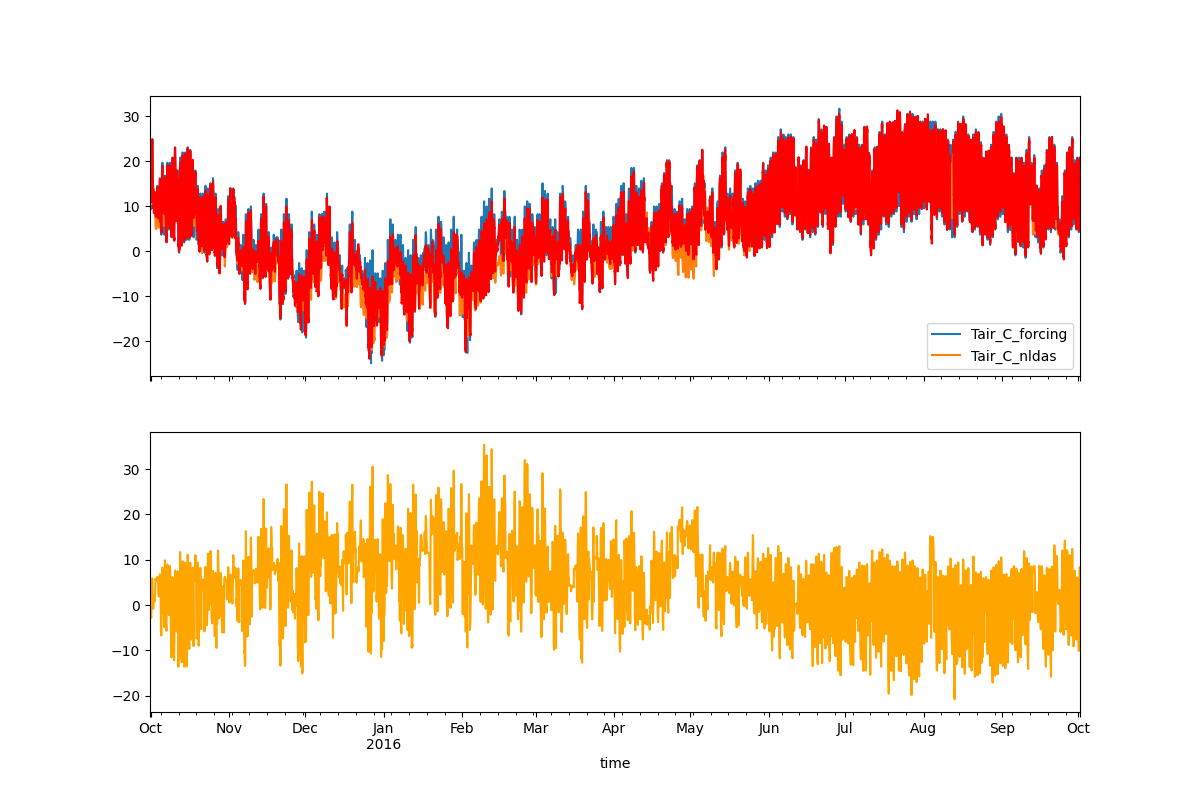

In [21]:
# Plot the lapserate
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 8))
forcing[['Tair_C_forcing','Tair_C_nldas']].plot(ax=axs[0])
gamut_st110['AirTemp_ST110_Avg'].plot(ax=axs[0], color='red', label='GAMUT ST110')
forcing['lapserate'].plot(ax=axs[1], color='orange')

In [ ]:
# Convert temperature from Kelvin to Celsius
forcing_Tair['Tair_C'] = forcing_Tair['Tair'] - 273.15
forcing_Tair.index = forcing_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

In [ ]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [ ]:
snotel.data.head()

In [ ]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [ ]:
nldas_Tair = nldas_forcing['Tair'].to_dataframe()
nldas_Tair['Tair_C'] = nldas_Tair['Tair'] - 273.15
nldas_Tair.index = nldas_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

#### Load GAMUT

In [ ]:
# Load gdriver credentials
credentials = get_credentials()

# Get the ST110 data
gamut_st110 = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

# Change index to DateTimeUTC
gamut_st110['DateTime'] = pd.to_datetime(gamut_st110['LocalDateTime'])
gamut_st110 = gamut_st110.set_index('DateTime')

# Convert -9999 to NaN
gamut_st110 = gamut_st110.replace(-9999, np.nan)

In [ ]:
# Extract a subset of the data for the time period of interest
start_date = '2015-01-01 00:00:00'
end_date = '2015-03-01 00:00:00'
gamut_st110_month = gamut_st110.loc[start_date:end_date]

# Localize datetime to america/denver timezone
gamut_st110_month.index = gamut_st110_month.index.tz_localize('America/Denver')

## Comparisons

In [ ]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', color='r', linestyle='-')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')
nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', color='k', linestyle='--')
snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='r', marker='*', linestyle='None')
snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='b', marker='*', linestyle='None')
ax.legend()
# fig, ax = plt.subplots(figsize=(12, 6))
# forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', style='r')
# gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', style='b-')
# nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', style='k--')
# snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='r*')
# snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='b*')
# ax.legend()

In [ ]:
# Load Tair V0 for comparison
sitename = site.replace(' ', '').lower()
datapath_v0 = os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_v0.1.0.nc')
forcing_Tair_v0 = get_forcing_values(datapath_v0, 'Tair', start_date, end_date)
forcing_Tair_v0['Tair_C'] = forcing_Tair_v0['Tair'] - 273.15
forcing_Tair_v0.index = forcing_Tair_v0.index.tz_localize('UTC').tz_convert('America/Denver')

In [ ]:
# Compare Tair V0 to V1
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair V1 (C)', color='r', linestyle='-')
forcing_Tair_v0['Tair_C'].plot(ax=ax, label='Forcing Tair V0 (C)', color='r', linestyle='--')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')


#